# 02 結果分析（作業 §7–§8）

需要先執行 `01_training.ipynb`，這本 notebook 會讀 `outputs/` 裡的模型、CV 結果與 test 預測。
**這裡不做任何模型選擇**，test 只用來分析已經固定的最終模型。

| 步驟 | 內容 | 對應論文段落 |
|---|---|---|
| 1 | 和每個 baseline / Set A、B 的顯著性檢定 | §7.1 |
| 2 | 資料切片的 MAE | §7.2 |
| 3 | 係數、95% CI、p 值、VIF、森林圖 | §8.1 |
| 4 | 假設 H1–H5 檢驗 | §8.1（回應 §4） |
| 5 | 最大誤差案例與殘差模式 | §8.2 |
| 6 | 決策門檻的補充：AQI 等級正確率 | §6.2、§7.1 |

In [1]:
import json
import sys
import warnings
from pathlib import Path

# 讓 notebook 不論從 repo 根目錄或 Model/ 開啟都找得到 features.py
MODEL_DIR = Path.cwd() if (Path.cwd() / "features.py").exists() else Path.cwd() / "Model"
sys.path.insert(0, str(MODEL_DIR))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

import features as F

F.setup_plotting()
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", 50, "display.width", 160)

import statsmodels.api as sm
from scipy import stats

In [2]:
data = F.load_hybrid()
X = F.build_frame(data)
y = data.y
train_mask, test_mask = data.is_train, ~data.is_train
# train 在前、test 在後（依時間切分）
assert train_mask[: train_mask.sum()].all() and not train_mask[train_mask.sum():].any()

X_train, y_train = X[train_mask].reset_index(drop=True), y[train_mask].reset_index(drop=True)
X_test, y_test = X[test_mask].reset_index(drop=True), y[test_mask].reset_index(drop=True)
time_train = data.time[train_mask].reset_index(drop=True)
time_test = data.time[test_mask].reset_index(drop=True)
assert (len(X_train), len(X_test)) == (6930, 1733)

run_info = json.loads((F.OUT / "run_info.json").read_text(encoding="utf-8"))
cv_results = pd.read_csv(F.OUT / "cv_results.csv", encoding="utf-8-sig")
predictions = pd.read_csv(F.OUT / "test_predictions.csv", encoding="utf-8-sig", parse_dates=["target_datetime"])
final_model = joblib.load(F.OUT / "final_model.joblib")
assert (predictions["target_datetime"] == time_test).all() and np.allclose(predictions["actual"], y_test)

FINAL = run_info["final_method"]
SET_A, SET_B, SET_C = (run_info["set_methods"][k] for k in "ABC")
THRESHOLD_MAE = run_info["threshold_mae"]
rng = np.random.default_rng(F.SEED)
run_info

{'final_name': 'Ridge',
 'final_method': 'Ridge + Set C',
 'final_params': {'model__alpha': 31.622776601683793},
 'strongest_baseline': 'Persistence (t-1)',
 'baselines': ['Training mean',
  'Persistence (t-1)',
  'Single-feature OLS (PM2.5 t-1)',
  'HistGradientBoosting (raw)'],
 'set_methods': {'A': 'Set A: all 162 raw columns',
  'B': 'Set B: top-k |Spearman| (in-fold)',
  'C': 'Set C: ours'},
 'threshold_mae': 3.0}

## 1. 顯著性檢定（§7.1）

最終模型和每個 baseline、Set A、Set B 逐一比較：

- **CV**：5 個 fold 的 MAE 做 paired t-test（`scipy.stats.ttest_rel`）。只有 5 個 fold，檢定力有限。
- **Test**：以 24 小時為一塊的 moving-block bootstrap（2000 次），計算 MAE 差距（最終模型 − 對照）的 95% CI。
  用整塊抽樣是為了保留每小時誤差之間的自相關。CI 不包含 0 時，代表差距在 test 上是穩定的。

In [3]:
N_BOOT, BLOCK = 2000, 24
fold_mae = cv_results.pivot_table(index="fold", columns="method", values="mae")
abs_err = predictions.drop(columns=["target_datetime", "actual"]).sub(predictions["actual"], axis=0).abs()
boot_idx = [F.block_bootstrap_indices(len(abs_err), BLOCK, rng) for _ in range(N_BOOT)]

rows = []
for other in run_info["baselines"] + [SET_A, SET_B]:
    t_stat, p_value = stats.ttest_rel(fold_mae[FINAL], fold_mae[other])
    gap = abs_err[FINAL] - abs_err[other]
    boot = np.array([gap.to_numpy()[idx].mean() for idx in boot_idx])
    rows.append({
        "compared_with": other,
        "cv_mae_gap_mean": (fold_mae[FINAL] - fold_mae[other]).mean(),
        "cv_mae_gap_std": (fold_mae[FINAL] - fold_mae[other]).std(),
        "paired_t": t_stat,
        "paired_t_p": p_value,
        "test_mae_gap": gap.mean(),
        "boot_ci_low": np.percentile(boot, 2.5),
        "boot_ci_high": np.percentile(boot, 97.5),
    })
significance = pd.DataFrame(rows)
significance["ci_excludes_0"] = (significance["boot_ci_low"] > 0) | (significance["boot_ci_high"] < 0)
F.save_table(significance.round(4), "significance")
print("差距 = 最終模型 − 對照（負值代表最終模型較好），單位 μg/m³")
significance.round(4)

差距 = 最終模型 − 對照（負值代表最終模型較好），單位 μg/m³


,compared_with,cv_mae_gap_mean,cv_mae_gap_std,paired_t,paired_t_p,test_mae_gap,boot_ci_low,boot_ci_high,ci_excludes_0
0,Training mean,-4.6085,1.5716,-6.5570,0.0028,-3.4876,-4.0102,-2.8850,True
1,Persistence (t-1),-0.1607,0.1428,-2.5159,0.0656,-0.0742,-0.1927,0.0475,False
2,Single-feature OLS (PM2.5 t-1),-0.2429,0.1662,-3.2684,0.0308,-0.1101,-0.1991,-0.0098,True
3,HistGradientBoosting (raw),-0.2693,0.2035,-2.9601,0.0415,-0.0545,-0.1315,0.0351,False
4,Set A: all 162 raw columns,-0.1195,0.0998,-2.6771,0.0554,0.0410,0.0023,0.0828,True
5,Set B: top-k |Spearman| (in-fold),-0.0025,0.0864,-0.0647,0.9515,0.0048,-0.0329,0.0423,False


## 2. 資料切片（§7.2）

在 test 上依下列條件切片，比較 persistence、強 baseline 與 Set A / B / C 的 MAE：
時段、上一小時是否下雨、上一小時風速分段、是否為高濃度（≥ train 的第 90 百分位數）、月份。

In [4]:
raw_test = data.R[test_mask].reset_index(drop=True)
high_cut = y_train.quantile(0.9)
hour = time_test.dt.hour


def period(h):
    if h >= 22 or h <= 5:
        return "night 22-05"
    if h <= 9:
        return "morning 06-09"
    return "day 10-16" if h <= 16 else "evening 17-21"


slices = pd.DataFrame({
    "time_of_day": hour.map(period),
    "rain_t-1": np.where(raw_test["RAINFALL_lag_1h"] > 0, "rain", "no rain"),
    "wind_speed_t-1": pd.cut(raw_test["WIND_SPEED_lag_1h"], [-np.inf, 1, 6, np.inf], right=False,
                             labels=["< 1 m/s", "1-6 m/s", ">= 6 m/s"]).astype(str),
    "concentration": np.where(y_test >= high_cut, f">= p90 ({high_cut:.0f} μg/m³)", f"< p90 ({high_cut:.0f} μg/m³)"),
    "month": time_test.dt.month.astype(str),
})

SLICE_METHODS = ["Persistence (t-1)", run_info["strongest_baseline"], SET_A, SET_B, SET_C]
SLICE_METHODS = list(dict.fromkeys(SLICE_METHODS))
slice_rows = []
for dimension in slices:
    for level, idx in slices.groupby(dimension).groups.items():
        row = {"slice": dimension, "level": level, "n": len(idx)}
        row.update({m: abs_err.loc[idx, m].mean() for m in SLICE_METHODS})
        slice_rows.append(row)
slice_mae = pd.DataFrame(slice_rows)
F.save_table(slice_mae.round(3), "slice_mae")
slice_mae.round(2)

,slice,level,n,Persistence (t-1),Set A: all 162 raw columns,Set B: top-k |Spearman| (in-fold),Set C: ours
0,time_of_day,day 10-16,498,2.57,2.44,2.53,2.45
1,time_of_day,evening 17-21,364,2.59,2.49,2.50,2.48
2,time_of_day,morning 06-09,288,2.47,2.48,2.52,2.61
3,time_of_day,night 22-05,583,2.55,2.38,2.38,2.43
4,rain_t-1,no rain,1637,2.58,2.46,2.49,2.51
5,rain_t-1,rain,96,1.97,2.01,2.12,1.87
6,wind_speed_t-1,1-6 m/s,1455,2.53,2.40,2.45,2.43
7,wind_speed_t-1,< 1 m/s,237,2.68,2.48,2.44,2.63
8,wind_speed_t-1,>= 6 m/s,11,1.27,1.53,1.99,2.18
9,wind_speed_t-1,nan,30,3.10,4.11,4.04,3.74


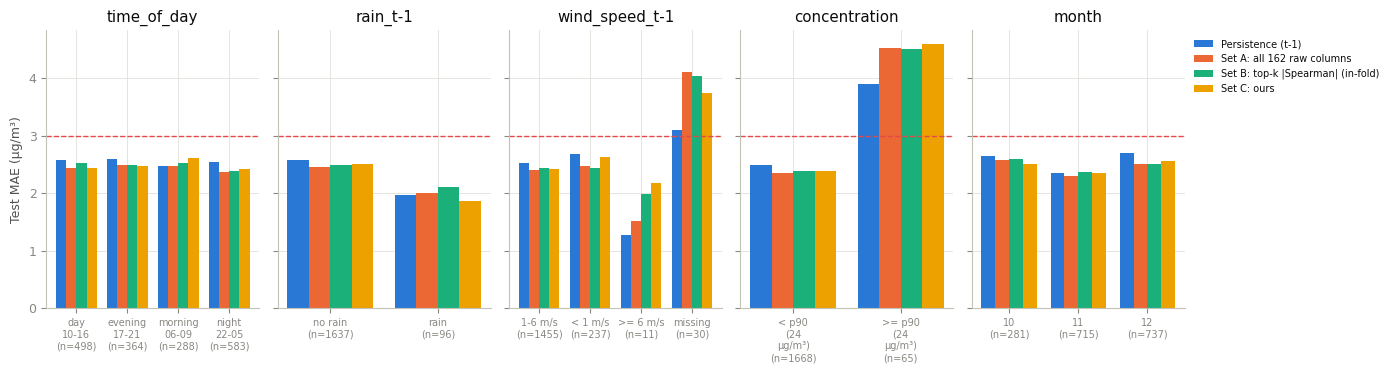

In [5]:
import textwrap

fig, axes = plt.subplots(1, len(slices.columns), figsize=(14, 3.8), sharey=True)
width = 0.8 / len(SLICE_METHODS)
for ax, dimension in zip(axes, slices.columns):
    part = slice_mae[slice_mae["slice"] == dimension].reset_index(drop=True)
    x = np.arange(len(part))
    for j, (method, color) in enumerate(zip(SLICE_METHODS, F.SERIES)):
        ax.bar(x + (j - (len(SLICE_METHODS) - 1) / 2) * width, part[method], width, color=color, label=method)
    # 標籤水平顯示、長的自動換行，避免相鄰標籤重疊；缺值組顯示為 missing
    labels = [textwrap.fill("missing" if lvl == "nan" else str(lvl), 8) + f"\n(n={n})" for lvl, n in zip(part["level"], part["n"])]
    ax.set_xticks(x, labels, fontsize=7)
    ax.set_title(dimension)
    ax.axhline(THRESHOLD_MAE, color=F.RED, linestyle="--", linewidth=1)
axes[0].set_ylabel("Test MAE (μg/m³)")
axes[-1].legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
F.save_fig(fig, "fig3_slice_mae")
plt.show()

## 3. 係數與統計顯著性（§8.1）

- 特徵都已標準化，所以係數 β 的單位是「每增加 1 個標準差，PM2.5 改變多少 μg/m³」，可以直接比較大小。
- **檢定**：在 train 上用相同的 Set C 特徵做 OLS，標準誤用 HAC / Newey–West（24 lags），因為每小時的殘差有自相關，一般的 t-test 會低估標準誤。
- 最終模型若是 Ridge / Lasso / ElasticNet，另外用 24 小時 moving-block bootstrap（300 次）重新 fit，得到懲罰後係數的 95% CI，確認方向和 OLS 一致。
- **實際顯著**：|β| ≥ 0.5 μg/m³ per SD 才算有實際意義（約為決策門檻 3 μg/m³ 的六分之一）。資料有數千列，很小的效果也會 p < 0.05。

In [6]:
PRACTICAL = 0.5  # μg/m³ per SD
prep = final_model.named_steps["prep"]
names = prep.get_feature_names_out()
Xc_train = pd.DataFrame(prep.transform(X_train), columns=names)

ols = sm.OLS(y_train.to_numpy(), sm.add_constant(Xc_train)).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
ci = ols.conf_int()

penalized = final_model.named_steps["model"]
boot_coefs = []
for _ in range(300):
    idx = F.block_bootstrap_indices(len(Xc_train), 24, rng)
    boot_coefs.append(clone(penalized).fit(Xc_train.iloc[idx], y_train.iloc[idx]).coef_)
boot_coefs = np.array(boot_coefs)

group_of = {c: g for g, cols in F.GROUPS.items() for c in cols}
coef = pd.DataFrame({
    "feature": names,
    "group": [group_of[n] for n in names],
    "beta_ols": ols.params[names].to_numpy(),
    "ci_low": ci.loc[names, 0].to_numpy(),
    "ci_high": ci.loc[names, 1].to_numpy(),
    "p_value": ols.pvalues[names].to_numpy(),
    "test": "OLS t-test, HAC (Newey-West, 24 lags)",
    "vif": F.vif(Xc_train)[names].to_numpy(),
    f"beta_{run_info['final_name']}": penalized.coef_,
    "boot_ci_low": np.percentile(boot_coefs, 2.5, axis=0),
    "boot_ci_high": np.percentile(boot_coefs, 97.5, axis=0),
})
coef["stat_significant"] = coef["p_value"] < 0.05
coef["practically_significant"] = coef["beta_ols"].abs() >= PRACTICAL
coef = coef.reindex(coef["beta_ols"].abs().sort_values(ascending=False).index).reset_index(drop=True)
F.save_table(coef.round(4), "coefficients")
print(f"OLS R² (train) = {ols.rsquared:.3f}；intercept = {ols.params['const']:.3f} μg/m³")
coef.round(3)

OLS R² (train) = 0.808；intercept = 12.383 μg/m³


,feature,group,beta_ols,ci_low,ci_high,p_value,test,vif,beta_Ridge,boot_ci_low,boot_ci_high,stat_significant,practically_significant
0,z_PM2.5_lag_1h,persistence,3.247,2.412,4.083,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",43.701,3.119,2.465,3.734,True,True
1,z_PM10_lag_1h,co_pollutants,2.789,2.226,3.351,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",9.830,2.686,2.174,3.201,True,True
2,eng_pm25_mean3h,pm25_aggregates,2.229,1.107,3.351,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",66.354,2.183,1.280,2.816,True,True
3,z_CO_lag_1h,co_pollutants,1.760,1.381,2.140,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",9.999,1.696,1.388,2.082,True,True
4,z_PM10_lag_3h,co_pollutants,-0.856,-1.221,-0.492,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",10.140,-0.849,-1.191,-0.528,True,True
5,z_PM10_lag_2h,co_pollutants,-0.749,-1.319,-0.179,0.010,"OLS t-test, HAC (Newey-West, 24 lags)",14.235,-0.634,-1.188,-0.141,True,True
6,z_CO_lag_2h,co_pollutants,-0.608,-1.069,-0.148,0.010,"OLS t-test, HAC (Newey-West, 24 lags)",11.821,-0.535,-0.947,-0.127,True,True
7,z_NO_lag_1h,co_pollutants,-0.474,-0.786,-0.161,0.003,"OLS t-test, HAC (Newey-West, 24 lags)",1.982,-0.470,-0.752,-0.124,True,False
8,z_AMB_TEMP_lag_1h,meteorology,-0.383,-0.543,-0.222,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",2.630,-0.382,-0.543,-0.202,True,False
9,eng_ws_lt1,wind_bins,0.368,0.225,0.511,0.000,"OLS t-test, HAC (Newey-West, 24 lags)",2.158,0.371,0.224,0.531,True,False


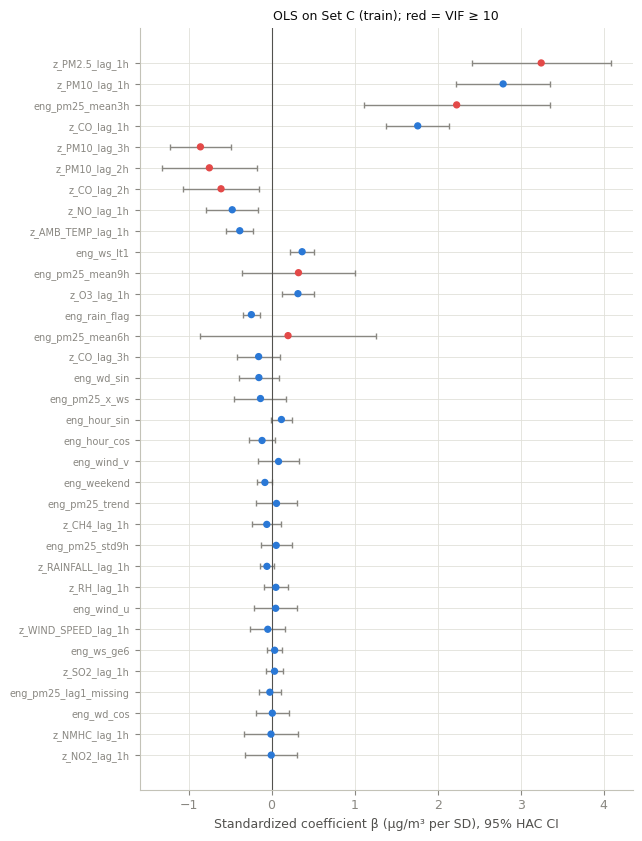

In [7]:
# 森林圖：β 與 95% CI；VIF ≥ 10 標紅，代表共線、解讀要小心
plot = coef.iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 0.22 * len(plot) + 1))
colors = np.where(plot["vif"] >= 10, F.RED, F.BLUE)
ax.errorbar(plot["beta_ols"], np.arange(len(plot)),
            xerr=[plot["beta_ols"] - plot["ci_low"], plot["ci_high"] - plot["beta_ols"]],
            fmt="none", ecolor=F.MUTED, elinewidth=1, capsize=2)
ax.scatter(plot["beta_ols"], np.arange(len(plot)), color=colors, s=18, zorder=3)
ax.axvline(0, color=F.INK2, linewidth=0.8)
ax.set_yticks(np.arange(len(plot)), plot["feature"], fontsize=7)
ax.set_xlabel("Standardized coefficient β (μg/m³ per SD), 95% HAC CI")
ax.set_title("OLS on Set C (train); red = VIF ≥ 10", fontsize=9)
F.save_fig(fig, "fig4_coefficients_forest")
plt.show()

## 4. 假設檢驗（回應 §4 的 H1–H5）

| 假設 | 檢驗方式 |
|---|---|
| H1 PM2.5(t−1) 是最主要的預測因子 | β(PM2.5 lag1) > 0 且 p < 0.05；拿掉 persistence 群後 CV MAE 上升 |
| H2 控制 PM2.5 後，PM10 / CO 仍有增量 | PM10 / CO 中至少一個 β > 0 且 p < 0.05；拿掉 co_pollutants 後 CV MAE 上升 |
| H3 風速效果為負且非線性（靜風時 PM2.5 偏高） | < 1 m/s 旗標 β > 0，或 ≥ 6 m/s 旗標、PM2.5 × 風速交互作用 β < 0（p < 0.05）；拿掉 wind_bins / interaction 後 CV MAE 上升 |
| H4 溫度的負相關主要反映季節 | 控制其他變數後的 \|β\| 小於單變量斜率（r × σ_y） |
| H5 聚合特徵優於原始 lag | Set C 的 CV MAE 低於「改回 lag 1–9h」的版本，且 5 個 fold 的配對差距 paired t-test p < 0.05；不顯著時判定為 inconclusive |

下表自動產出證據與初步判定（yes / no / inconclusive）。CV MAE 的差距要和 fold 間標準差一起看，寫論文時再人工確認。

In [8]:
by_feature = coef.set_index("feature")
ablation = pd.read_csv(F.TAB / "ablation.csv", encoding="utf-8-sig").set_index("method")
delta = ablation["delta_mae_vs_C"]
fold_std = ablation.loc[SET_C, "cv_mae_std"]


def effect(name):
    row = by_feature.loc[name]
    return f"β={row.beta_ols:+.2f} (p={row.p_value:.3g})"


def positive_sig(name):
    return name in by_feature.index and by_feature.loc[name, "beta_ols"] > 0 and by_feature.loc[name, "p_value"] < 0.05


def negative_sig(name):
    return name in by_feature.index and by_feature.loc[name, "beta_ols"] < 0 and by_feature.loc[name, "p_value"] < 0.05


co_feats = [c for c in F.GROUPS["co_pollutants"] if c.startswith(("z_PM10", "z_CO"))]
marginal = np.corrcoef(Xc_train["z_AMB_TEMP_lag_1h"], y_train)[0, 1] * y_train.std(ddof=0)
# H5：同一組 folds 的配對差距做 paired t-test，差距不顯著就判定為無法區分
RAW_LAGS = "Set C with PM2.5 lags 1-9h instead of aggregates"
h5_folds = fold_mae[RAW_LAGS] - fold_mae[SET_C]
h5_gap = h5_folds.mean()
h5_p = stats.ttest_rel(fold_mae[RAW_LAGS], fold_mae[SET_C]).pvalue
h5_verdict = "inconclusive" if h5_p >= 0.05 else ("yes" if h5_gap > 0 else "no")

hypotheses = pd.DataFrame([
    {"hypothesis": "H1 persistence dominates",
     "evidence": f"{effect('z_PM2.5_lag_1h')}; ΔMAE without persistence = {delta['Set C - persistence']:+.3f}",
     "supported": positive_sig("z_PM2.5_lag_1h") and delta["Set C - persistence"] > 0},
    {"hypothesis": "H2 PM10/CO add information",
     "evidence": "; ".join(effect(c) + " " + c for c in co_feats) + f"; ΔMAE without co_pollutants = {delta['Set C - co_pollutants']:+.3f}",
     "supported": any(positive_sig(c) for c in co_feats) and delta["Set C - co_pollutants"] > 0},
    {"hypothesis": "H3 wind effect negative and nonlinear",
     "evidence": f"ws<1 {effect('eng_ws_lt1')}; ws>=6 {effect('eng_ws_ge6')}; PM2.5×ws {effect('eng_pm25_x_ws')}; "
                 f"ΔMAE without wind_bins = {delta['Set C - wind_bins']:+.3f}, without interaction = {delta['Set C - interaction']:+.3f}",
     "supported": (positive_sig("eng_ws_lt1") or negative_sig("eng_ws_ge6") or negative_sig("eng_pm25_x_ws"))
                  and max(delta["Set C - wind_bins"], delta["Set C - interaction"]) > 0},
    {"hypothesis": "H4 temperature mostly reflects season",
     "evidence": f"marginal slope {marginal:+.2f} vs {effect('z_AMB_TEMP_lag_1h')} (μg/m³ per SD)",
     "supported": abs(by_feature.loc["z_AMB_TEMP_lag_1h", "beta_ols"]) < abs(marginal)},
    {"hypothesis": "H5 aggregates beat raw lags",
     "evidence": f"CV MAE(raw lags) − CV MAE(Set C) = {h5_gap:+.3f} "
                 f"(paired fold std = {h5_folds.std():.3f}, paired t-test p = {h5_p:.3g}); fold std = {fold_std:.3f}",
     "supported": h5_verdict},
])
hypotheses["supported"] = hypotheses["supported"].map(lambda v: {True: "yes", False: "no"}.get(v, v))
F.save_table(hypotheses, "hypotheses")
hypotheses

,hypothesis,evidence,supported
0,H1 persistence dominates,β=+3.25 (p=2.58e-14); ΔMAE without persistence...,yes
1,H2 PM10/CO add information,β=+2.79 (p=2.47e-22) z_PM10_lag_1h; β=-0.75 (p...,yes
2,H3 wind effect negative and nonlinear,ws<1 β=+0.37 (p=4.35e-07); ws>=6 β=+0.04 (p=0....,yes
3,H4 temperature mostly reflects season,marginal slope -2.86 vs β=-0.38 (p=3.03e-06) (...,yes
4,H5 aggregates beat raw lags,CV MAE(raw lags) − CV MAE(Set C) = +0.006 (pai...,inconclusive


## 5. 錯誤分析（§8.2）

列出 test 上誤差最大的 5 筆（誤差 = 實際 − 預測，單位 μg/m³），附上當時的輸入。
`hint` 欄是依規則自動產生的可能原因，寫論文時請逐筆確認：

- `abrupt change`：實際值和上一小時差超過 10 μg/m³，歷史資料看不出來的突然變化。
- `rain washout`：上一小時有下雨。
- `strong wind`：上一小時風速 ≥ 6 m/s（train 中樣本少，屬於外插）。
- `missing input`：PM2.5(t−1) 是補值。

In [9]:
residual = predictions["actual"] - predictions[FINAL]
top = residual.abs().nlargest(5).index
context_cols = ["PM2.5_lag_1h", "PM2.5_lag_2h", "PM2.5_lag_3h", "PM10_lag_1h", "WIND_SPEED_lag_1h",
                "WIND_DIREC_lag_1h", "RAINFALL_lag_1h", "AMB_TEMP_lag_1h", "RH_lag_1h"]


def hint(i):
    reasons = []
    lag1 = raw_test.loc[i, "PM2.5_lag_1h"]
    if pd.isna(lag1):
        reasons.append("missing input")
    elif abs(predictions.loc[i, "actual"] - lag1) > 10:
        reasons.append("abrupt change")
    if raw_test.loc[i, "RAINFALL_lag_1h"] > 0:
        reasons.append("rain washout")
    if raw_test.loc[i, "WIND_SPEED_lag_1h"] >= 6:
        reasons.append("strong wind")
    return ", ".join(reasons)


cases = pd.DataFrame({
    "time": predictions.loc[top, "target_datetime"].dt.strftime("%m-%d %H:%M"),
    "actual": predictions.loc[top, "actual"],
    "predicted": predictions.loc[top, FINAL],
    "error": residual[top],
}).join(raw_test.loc[top, context_cols])
cases["hint"] = [hint(i) for i in top]
cases.insert(0, "#", range(1, len(cases) + 1))
F.save_table(cases.round(2), "largest_errors")
cases.round(1)

,#,time,actual,predicted,error,PM2.5_lag_1h,PM2.5_lag_2h,PM2.5_lag_3h,PM10_lag_1h,WIND_SPEED_lag_1h,WIND_DIREC_lag_1h,RAINFALL_lag_1h,AMB_TEMP_lag_1h,RH_lag_1h,hint
1475,1,12-21 04:00,27.0,10.0,17.0,11.0,12.0,10.0,17.0,3.5,39.0,0.0,21.7,89.0,abrupt change
73,2,10-23 07:00,19.0,2.1,16.9,0.0,0.0,0.0,7.0,4.1,41.0,0.0,22.9,94.0,abrupt change
1476,3,12-21 05:00,42.0,27.1,14.9,27.0,11.0,12.0,59.0,3.5,36.0,0.0,21.1,89.0,abrupt change
74,4,10-23 08:00,0.0,13.6,-13.6,19.0,0.0,0.0,17.0,3.2,45.0,0.0,23.4,93.0,abrupt change
342,5,11-03 13:00,4.0,17.5,-13.5,20.0,19.0,16.0,30.0,4.9,52.0,0.0,23.4,70.0,abrupt change


In [10]:
# 共同模式：殘差和「這一小時的變化量」（actual − PM2.5 t−1）的關係
change = predictions["actual"] - raw_test["PM2.5_lag_1h"]
ok = change.notna()
r_change = np.corrcoef(change[ok], residual[ok])[0, 1]
print(f"殘差與小時變化量的相關係數 r = {r_change:.3f}")
print("各月份平均殘差（μg/m³）：")
print(residual.groupby(time_test.dt.month).agg(["mean", "count"]).round(2))

殘差與小時變化量的相關係數 r = 0.867
各月份平均殘差（μg/m³）：
                 mean  count
target_datetime             
10              -0.80    281
11              -0.72    715
12              -0.83    737


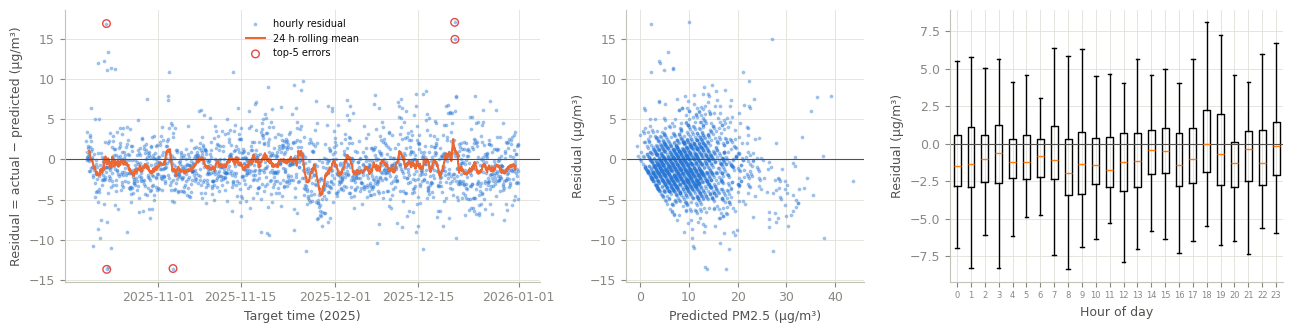

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw={"width_ratios": [2, 1, 1.4]})

ax = axes[0]
ax.scatter(time_test, residual, s=3, color=F.BLUE, alpha=0.35, label="hourly residual")
ax.plot(time_test, residual.rolling(24, center=True).mean(), color=F.ORANGE, linewidth=1.5, label="24 h rolling mean")
ax.axhline(0, color=F.INK2, linewidth=0.8)
ax.scatter(time_test[top], residual[top], s=30, facecolors="none", edgecolors=F.RED, label="top-5 errors")
ax.set_xlabel("Target time (2025)")
ax.set_ylabel("Residual = actual − predicted (μg/m³)")
ax.legend(frameon=False, fontsize=7)

ax = axes[1]
ax.scatter(predictions[FINAL], residual, s=3, color=F.BLUE, alpha=0.35)
ax.axhline(0, color=F.INK2, linewidth=0.8)
ax.set_xlabel("Predicted PM2.5 (μg/m³)")
ax.set_ylabel("Residual (μg/m³)")

ax = axes[2]
ax.boxplot([residual[hour == h] for h in range(24)], tick_labels=[str(h) for h in range(24)], showfliers=False)
ax.axhline(0, color=F.INK2, linewidth=0.8)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Residual (μg/m³)")
ax.tick_params(axis="x", labelsize=6)

F.save_fig(fig, "fig5_residuals")
plt.show()

## 6. 決策門檻的補充：AQI 等級正確率（§6.2、§7.1）

決策門檻（MAE ≤ 3 μg/m³）以 AQI 的 PM2.5 分級寬度為尺度，但 AQI 不是用單一小時濃度計算的：

- **即時 AQI** 的 PM2.5 濃度 = 0.5 × 前 12 小時平均 + 0.5 × 前 4 小時平均（兩個窗口都包含 t）。
- **日 AQI** 的分級本身是用 24 小時平均值定義的。

到 t 時刻，兩個窗口裡只有 t 這一小時是預測值，其餘都已經量測到。所以下一小時的預測誤差 e 傳到即時 AQI 濃度時會被稀釋：

AQI 濃度誤差 = 0.5 × e / 12 + 0.5 × e / 4 = **e / 6**

下表在 test 上比較兩種等級判斷（界線 12.5 / 30.5 / 50.5 μg/m³）：

- **單一小時值**：直接用預測的小時濃度判斷等級，對應本研究的應用情境（看下一小時的濃度決定是否外出）。
- **即時 AQI 公式**：把預測值放進即時 AQI 的移動平均後再判斷等級。

缺值小時直接略過，沒有套用官方「4 小時至少 2 筆、12 小時至少 6 筆有效」的規則（test 缺值很少，影響不大）。
這是看過 test 結果後補做的分析，只用來解讀門檻，不影響任何模型或門檻的選擇。

In [12]:
# 所有有效的小時實測值（無效小時不在 index 裡，計算平均時自然略過）
hourly = pd.Series(data.y.to_numpy(), index=data.time)
AQI_BINS = [12.5, 30.5, 50.5]  # 良好 | 普通 | 對敏感族群不健康 | 對所有族群不健康以上


def realtime_conc(t, value_t):
    # 即時 AQI 的 PM2.5 濃度：t 用給定的值（預測或實測），t−11 到 t−1 用實測值
    past = hourly[(hourly.index >= t - pd.Timedelta(hours=11)) & (hourly.index < t)]
    last4 = past[past.index >= t - pd.Timedelta(hours=3)]
    return 0.5 * np.append(past.to_numpy(), value_t).mean() + 0.5 * np.append(last4.to_numpy(), value_t).mean()


actual_rt = np.array([realtime_conc(t, v) for t, v in zip(time_test, y_test)])
rows = []
for method in SLICE_METHODS:
    p = predictions[method].to_numpy()
    p_rt = np.array([realtime_conc(t, v) for t, v in zip(time_test, p)])
    rows.append({
        "method": method,
        "hourly_mae": np.abs(p - y_test.to_numpy()).mean(),
        "category_acc_hourly_%": (np.digitize(p, AQI_BINS) == np.digitize(y_test, AQI_BINS)).mean() * 100,
        "category_acc_realtime_aqi_%": (np.digitize(p_rt, AQI_BINS) == np.digitize(actual_rt, AQI_BINS)).mean() * 100,
        "realtime_aqi_conc_mae": np.abs(p_rt - actual_rt).mean(),
    })
aqi_accuracy = pd.DataFrame(rows)
aqi_accuracy["conc_mae_ratio"] = aqi_accuracy["realtime_aqi_conc_mae"] / aqi_accuracy["hourly_mae"]
F.save_table(aqi_accuracy.round(3), "aqi_category_accuracy")
print("conc_mae_ratio 應接近 1/6 ≈ 0.167")
aqi_accuracy.round(3)

conc_mae_ratio 應接近 1/6 ≈ 0.167


,method,hourly_mae,category_acc_hourly_%,category_acc_realtime_aqi_%,realtime_aqi_conc_mae,conc_mae_ratio
0,Persistence (t-1),2.550,84.651,97.692,0.432,0.169
1,Set A: all 162 raw columns,2.435,87.478,97.980,0.414,0.170
2,Set B: top-k |Spearman| (in-fold),2.471,86.209,97.865,0.421,0.170
3,Set C: ours,2.476,86.440,97.807,0.420,0.170


- 即時 AQI 濃度的誤差約為每小時 MAE 的 1/6，和推導一致。換算到即時 AQI 後，3 μg/m³ 的門檻只剩約 0.5 μg/m³，所以這個門檻對 AQI 用途是**保守的**。
- 即時 AQI 有 11/12 的資訊已經量測到，連 persistence 的等級正確率都接近 98%，下一小時預測對「AQI 等級」的幫助很小。
- 因此本研究的應用情境以**小時濃度**為準：對應的是「單一小時值」的等級正確率，各方法的差距才看得出來。

### 寫論文時要回答的問題（§8）

- **§8.1**：哪些係數同時統計顯著又有實際意義？有沒有方向和 §4 的相關係數相反的（例如溫度）？用 VIF 和共線解釋。
- **§8.2**：5 筆最大誤差各自的原因（逐筆確認 `hint`）；殘差和小時變化量的相關係數若明顯為正，代表模型在濃度突增時預測落後，
  第一個要嘗試的修正是加入能提前反映變化的資訊（例如上風處測站，或氣象預報）。
- **§9 限制**：只有 2025 年單一測站；test 期間的季節（11–12 月）在 train 中沒有；穩健性檢查（`tables/robustness_in_fold_scaling.csv`）的結果。